In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All packages are working!")

All packages are working!


In [5]:


student_data = pd.read_csv("student_data.csv")

student_data

,Student_ID,Name,Study_Hours,Attendance,Previous_Marks,Final_Marks
0,101,Aarav,2,75,60,65
1,102,Diya,4,82,68,72
2,103,Rohan,5,88,75,81
3,104,Ananya,6,90,80,86
4,105,Vivaan,3,78,65,69
5,106,Ishita,7,94,85,91
6,107,Arjun,1,68,55,58
7,108,Meera,5,86,72,79
8,109,Kabir,4,80,70,74
9,110,Saanvi,8,96,90,94


In [6]:
# means how many rows and columns
student_data.shape

(20, 6)

In [7]:
# cheack columns
student_data.columns

Index(['Student_ID', 'Name', 'Study_Hours', 'Attendance', 'Previous_Marks',
       'Final_Marks'],
      dtype='str')

In [8]:
student_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Student_ID      20 non-null     int64
 1   Name            20 non-null     str  
 2   Study_Hours     20 non-null     int64
 3   Attendance      20 non-null     int64
 4   Previous_Marks  20 non-null     int64
 5   Final_Marks     20 non-null     int64
dtypes: int64(5), str(1)
memory usage: 1.1 KB


In [9]:
student_data.describe()

,Student_ID,Study_Hours,Attendance,Previous_Marks,Final_Marks
count,20.00000,20.000000,20.000000,20.00000,20.000000
mean,110.50000,4.550000,83.900000,72.75000,77.600000
std,5.91608,2.089447,8.771365,11.07332,11.445063
min,101.00000,1.000000,68.000000,55.00000,58.000000
25%,105.75000,3.000000,77.500000,64.75000,68.750000
50%,110.50000,4.500000,85.000000,72.50000,78.000000
75%,115.25000,6.000000,91.250000,81.25000,87.250000
max,120.00000,8.000000,96.000000,90.00000,94.000000


In [10]:
#check missing values if 0 is output then no missing values 
student_data.isnull().sum()

Student_ID        0
Name              0
Study_Hours       0
Attendance        0
Previous_Marks    0
Final_Marks       0
dtype: int64

In [11]:
# check duplicate rows
student_data.duplicated().sum()

np.int64(0)

In [12]:
# check the data types
student_data.dtypes

Student_ID        int64
Name                str
Study_Hours       int64
Attendance        int64
Previous_Marks    int64
Final_Marks       int64
dtype: object

In [13]:
# attendance is between 0 to 100
student_data["Attendance"].min(), student_data["Attendance"].max()

(np.int64(68), np.int64(96))

In [14]:
# now check marks
student_data[["Previous_Marks","Final_Marks"]].min()

Previous_Marks    55
Final_Marks       58
dtype: int64

In [15]:
student_data[["Previous_Marks", "Final_Marks"]].max()

Previous_Marks    90
Final_Marks       94
dtype: int64

In [16]:
# find avrg(the avg student study 4.55 hr,attendance 84.65, and scores 77.65 marks)
student_data[["Study_Hours","Attendance","Previous_Marks","Final_Marks"]].mean()

Study_Hours        4.55
Attendance        83.90
Previous_Marks    72.75
Final_Marks       77.60
dtype: float64

In [17]:
student_data["Final_Marks"].max()

np.int64(94)

In [18]:
student_data["Final_Marks"].min()


np.int64(58)

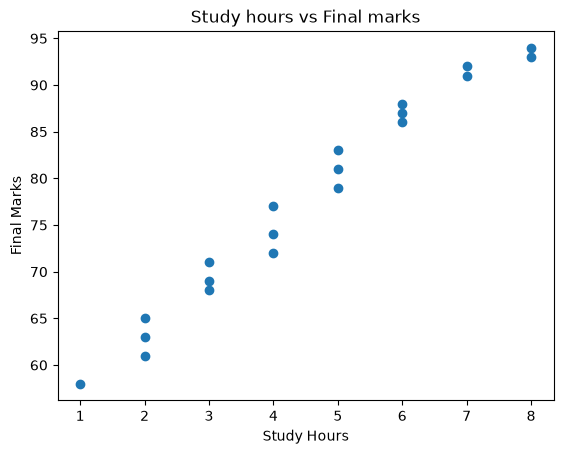

In [19]:
# study time have relationship with final marks?
import matplotlib.pyplot as plt

plt.scatter(student_data["Study_Hours"],student_data["Final_Marks"])
plt.xlabel("Study Hours")
plt.ylabel("Final Marks")
plt.title("Study hours vs Final marks")

plt.show()

In [20]:
# calculate the relationship numerically
# calculate the correlation

student_data["Study_Hours"].corr(student_data["Final_Marks"])


np.float64(0.9868755961321836)

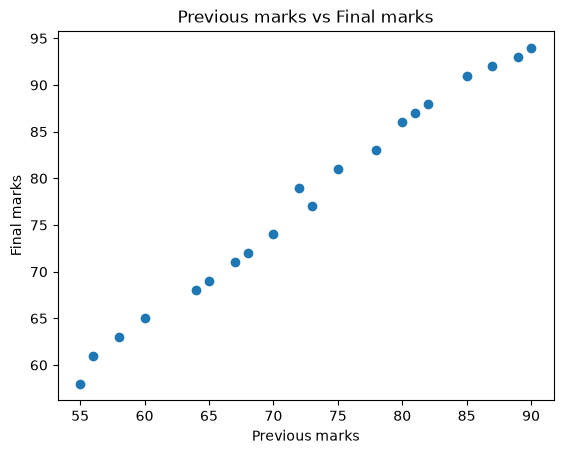

In [21]:
# DATA ANALYSIS PART.


# previous marks vr final marks

plt.scatter(student_data["Previous_Marks"], student_data["Final_Marks"])

plt.xlabel("Previous marks")
plt.ylabel("Final marks")


plt.title("Previous marks vs Final marks")
plt.show()

In [22]:
# calculate correlation

student_data["Previous_Marks"].corr(student_data["Final_Marks"])

np.float64(0.9962781111771866)

### Study Hours - Final Marks
### Attendance - Final Marks
### Previous Marks - Final Marks
### (Compared with Final marks)

In [23]:
correlations={
    "Study hours": student_data["Study_Hours"].corr(student_data["Final_Marks"]),
    "Attendance": student_data["Attendance"].corr(student_data["Final_Marks"]),
    "Previous Marks": student_data["Previous_Marks"].corr(student_data["Final_Marks"])
}

correlations

{'Study hours': np.float64(0.9868755961321836),
 'Attendance': np.float64(0.992561711239188),
 'Previous Marks': np.float64(0.9962781111771866)}

In [24]:
# Which factor in our dataset has the strongest relationship with Final Marks?

strongest_factor = max(correlations, key=lambda x: abs(correlations[x]))

print("Strongest factor:", strongest_factor)
print("correlation:", correlations[strongest_factor])

Strongest factor: Previous Marks
correlation: 0.9962781111771866


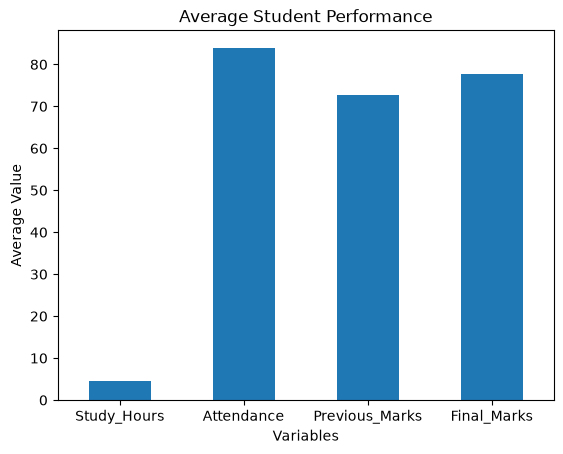

In [25]:
# Create simple summary

student_data[["Study_Hours", "Attendance", "Previous_Marks", "Final_Marks"]].mean().plot(kind="bar")

plt.xlabel("Variables")
plt.ylabel("Average Value")
plt.title("Average Student Performance")
plt.xticks(rotation=0)

plt.show()

In [26]:
## Use study hours,attendance, and previous marks to predict a students final marks
# using linear regression bcz its good first ML modal predicting numerical 
# value like marks
# seperate I/P & O/P
# X-information we give the model(study hr, attendance, previous marks)
# Y-what we want the model to predict(final_marks)

In [27]:
X= student_data[["Study_Hours", "Attendance", "Previous_Marks"]]
Y= student_data["Final_Marks"]

print("Input features:")
print(X.head())

print("\nTarget:")
print(Y.head())

Input features:
   Study_Hours  Attendance  Previous_Marks
0            2          75              60
1            4          82              68
2            5          88              75
3            6          90              80
4            3          78              65

Target:
0    65
1    72
2    81
3    86
4    69
Name: Final_Marks, dtype: int64


# NOW-Split the data
# 80%- training data= 16 students
# 20%- testing data= 4 students

In [28]:
from sklearn.model_selection import train_test_split

In [29]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

In [30]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16, 3)
Testing data: (4, 3)


In [31]:
# linear_regression creates the machine learning model.
from sklearn.linear_model import LinearRegression
model= LinearRegression()

In [32]:
model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0.75,0.56,0.45]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['Study_Hours','Attendance','Previous_Marks']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-5.372
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


# Make predictions

In [33]:
Y_pred= model.predict(X_test)
print("\n actual final marks:")
print(Y_test.values)

print("\n Predicted final marks:")
print(Y_pred)
      


 actual final marks:
[65 87 83 72]

 Predicted final marks:
[65.11935132 87.05570649 83.28004028 74.1267812 ]


# Evalute the model
# Using 2 importance metrics:
# 1.MAE(mean absolute error --> Avg number of marks the prediction is away from the actual mark.Lower is better
# 2.R^2 score --> Shows how welll the model explains the variation in the target. Closer to 1 is better.

In [34]:
from sklearn.metrics import mean_absolute_error, r2_score

mae= mean_absolute_error(Y_test, Y_pred)
r2= r2_score(Y_test, Y_pred)

print("Mean absolute error:", mae)
print("R2 score:", r2)

Mean absolute error: 0.645469822250444
R2 score: 0.9848434166491228


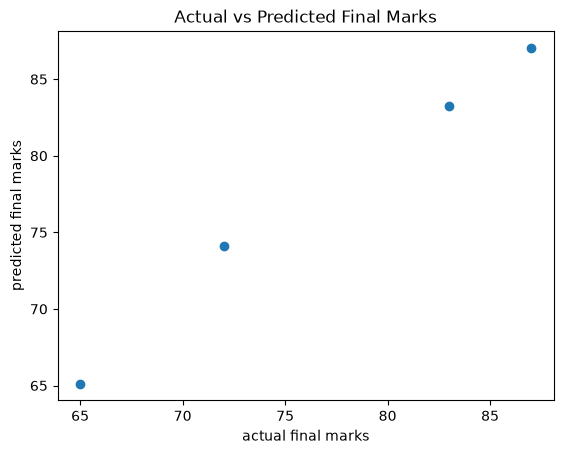

In [35]:
# ACTUAL VS PREDICTED MARKS

plt.scatter(Y_test, Y_pred)

plt.xlabel("actual final marks")
plt.ylabel("predicted final marks")
plt.title("Actual vs Predicted Final Marks")

plt.show()

In [ ]:
# predict marks for a new student
# example- study hr=5,attendance=85, previous marks=75


In [40]:
new_student= pd.DataFrame({
    "Study_Hours":[5],
    "Attendance":[85],
    "Previous_Marks":[75]
})

prediction= model.predict(new_student)

print("predicted final marks:", prediction[0])

# I trained a Linear Regression model and used it to predict the final marks of
# a new student based on study hours, attendance, and previous marks.

predicted final marks: 79.68963508488235


# Generate FINAL PROJECTS insights

In [44]:
print("==== PROJECT INSIGHT ====")

print("Average Study hr:",round(student_data["Study_Hours"].mean(),2))


print("Average Attendance:",round(student_data["Attendance"].mean(), 2), "%")

print("Average Previous Marks:",round(student_data["Previous_Marks"].mean(), 2))

print("Average Final Marks:",round(student_data["Final_Marks"].mean(), 2))

print("Highest Final Marks:",student_data["Final_Marks"].max())

print("Lowest Final Marks:",student_data["Final_Marks"].min())

print("Strongest Factor:",strongest_factor)

print("Strongest Correlation:",round(correlations[strongest_factor], 4))

print("Model MAE:",round(mae, 4))

print("Model R^2 Score:",round(r2, 4))

print("New Student Predicted Marks:",round(prediction[0], 2))


==== PROJECT INSIGHT ====
Average Study hr: 4.55
Average Attendance: 83.9 %
Average Previous Marks: 72.75
Average Final Marks: 77.6
Highest Final Marks: 94
Lowest Final Marks: 58
Strongest Factor: Previous Marks
Strongest Correlation: 0.9963
Model MAE: 0.6455
Model R^2 Score: 0.9848
New Student Predicted Marks: 79.69


In [47]:
def performance_category(marks):
    if marks >= 85:
        return "Excellent"
    elif marks >= 75:
        return "Good"
    elif marks >= 60:
        return "Average"
    else:
        return "Need Improvement"

student_data["Performance"] = student_data["Final_Marks"].apply(performance_category)

In [48]:
student_data[["Name", "Final_Marks", "Performance"]]

,Name,Final_Marks,Performance
0,Aarav,65,Average
1,Diya,72,Average
2,Rohan,81,Good
3,Ananya,86,Excellent
4,Vivaan,69,Average
5,Ishita,91,Excellent
6,Arjun,58,Need Improvement
7,Meera,79,Good
8,Kabir,74,Average
9,Saanvi,94,Excellent


# prepare the data for power bi

In [51]:
student_data.to_csv("student_performance_final.csv", index=False)

print("Final dataset saved successfully!")

Final dataset saved successfully!


In [52]:
student_data.head()

,Student_ID,Name,Study_Hours,Attendance,Previous_Marks,Final_Marks,Performance
0,101,Aarav,2,75,60,65,Average
1,102,Diya,4,82,68,72,Average
2,103,Rohan,5,88,75,81,Good
3,104,Ananya,6,90,80,86,Excellent
4,105,Vivaan,3,78,65,69,Average
